# Лабораторная работа №1: регрессия

Датасет: [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) из UCI Machine Learning Repository. По физико-химическим характеристикам вина нужно предсказать его оценку `quality`, которую выставили эксперты (целое число по шкале от 0 до 10).

Красное и белое вино обрабатываю вместе в одной таблице, тип вина кодирую бинарным признаком `is_red`.

Основная метрика — RMSE, дополнительная — MAE. Порог по заданию: RMSE < 0.70.

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set_theme(style="darkgrid")

RANDOM_STATE = 42

# Часть 1. Загружаем данные

Красное и белое вино лежат на UCI в двух отдельных csv-файлах (разделитель `;`). Склеиваю их в одну таблицу и добавляю признак `is_red` (1 — красное, 0 — белое), чтобы модель знала, какого типа вино.

In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"
red = pd.read_csv(url + "winequality-red.csv", sep=";")
white = pd.read_csv(url + "winequality-white.csv", sep=";")

red["is_red"] = 1
white["is_red"] = 0

data = pd.concat([red, white], ignore_index=True)
print("Красное:", red.shape, " Белое:", white.shape, " Всего:", data.shape)
data.head()

Красное: (1599, 13)  Белое: (4898, 13)  Всего: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


Пропусков нет, все признаки числовые (11 физико-химических измерений + `is_red`), поэтому заполнять пропуски и кодировать категории не нужно. Целевая переменная `quality` — целое число, но решаем задачу регрессии, т.е. модель предсказывает вещественное число.

Отдельно проверю дубликаты.

In [5]:
features_only = list(data.columns.drop("quality"))

print("Полных дубликатов строк:", data.duplicated().sum())
print("Дубликатов только по признакам (без quality):", data[features_only].duplicated().sum())
print("Групп с одинаковыми признаками, но разной оценкой:", (data.groupby(features_only)["quality"].nunique() > 1).sum())

# насколько далеко друг от друга копии стоят в исходных файлах
for name, df in [("красное", red), ("белое", white)]:
    dups = df[df.duplicated(keep=False)].reset_index()
    span = dups.groupby(list(df.columns))["index"].agg(lambda s: s.max() - s.min())
    print("%s: медианное расстояние между копиями = %d строк, доля копий в пределах 5 строк = %.2f" % (name, span.median(), (span <= 5).mean()))

Полных дубликатов строк: 1177
Дубликатов только по признакам (без quality): 1177
Групп с одинаковыми признаками, но разной оценкой: 0
красное: медианное расстояние между копиями = 2 строк, доля копий в пределах 5 строк = 0.92
белое: медианное расстояние между копиями = 4 строк, доля копий в пределах 5 строк = 0.60


Получается, что примерно 18% строк (1177 из 6497) — точные копии других строк. При этом:
- нет ни одного случая, когда у вин с одинаковыми 11 измерениями разная оценка;
- копии в исходных файлах обычно стоят рядом (у красного в 92% случаев копии находятся в пределах 5 строк друг от друга);
- у признаков десятки и сотни разных значений, так что разным винам случайно совпасть сразу по всем 11 измерениям очень маловероятно.

Скорее всего, это повторные записи одного и того же вина (например, несколько бутылок одной партии), а не разные вина с одинаковыми характеристиками. Но проверить это точно нельзя — в описании датасета на UCI я про это ничего не нашёл.

Удалять их я не стал: это наблюдения из исходного датасета, и скрытая тестовая выборка, скорее всего, тоже содержит такие повторы. Но надо помнить о последствиях: если одна копия попала в train, а другая в test (или в разные фолды кросс-валидации), то для модели это уже «знакомый» объект, и оценка качества получается оптимистичной. Насколько сильно — проверю в анализе ошибок (часть 11).

Если нужен вариант без дубликатов, достаточно раскомментировать строку в ячейке ниже и перезапустить весь ноутбук.

In [6]:
# вариант без дубликатов: раскомментировать строку ниже и перезапустить ноутбук
# data = data.drop_duplicates().reset_index(drop=True)

print(data.shape)

(6497, 13)


# Часть 2. Подготовка выборок

Делю данные на train и test **до** исследовательского анализа. Всё, что я дальше смотрю (распределения, корреляции), смотрю только на train, чтобы выводы и выбор признаков/моделей никак не зависели от ответов тестовой выборки.

In [7]:
from sklearn.model_selection import train_test_split

y = data["quality"]
X = data.drop(columns=["quality"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Доля красного вина в train / test: %.3f / %.3f" % (X_train["is_red"].mean(), X_test["is_red"].mean()))
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).sort_index().round(4)

Train: (5197, 12)  Test: (1300, 12)
Доля красного вина в train / test: 0.249 / 0.235


,train,test
quality,,
3,0.0046,0.0046
4,0.0333,0.0331
5,0.3290,0.3292
6,0.4366,0.4362
7,0.1661,0.1662
8,0.0296,0.0300
9,0.0008,0.0008


**Размер выборок.** Взял 80% / 20%: 5197 объектов в train и 1300 в test. Данных не очень много, поэтому большую часть оставляю на обучение (особенно деревьям важен объём данных), а 1300 объектов в тесте достаточно, чтобы оценка RMSE была стабильной. Подбирать гиперпараметры буду кросс-валидацией внутри train, поэтому отдельная валидационная выборка не нужна.

**Способ разбиения.** Случайное разбиение со стратификацией по `quality`. Оценки сильно несбалансированы: вин с оценкой 3 и 9 единицы (с оценкой 9 всего 5 вин во всём датасете). При обычном случайном разбиении редкие оценки могли бы почти целиком попасть в одну из частей, и тест перестал бы отражать реальное распределение. Стратификация сохраняет доли каждой оценки одинаковыми в train и test (это видно в таблице выше). Доля красного вина тоже получилась примерно одинаковой (0.249 и 0.235). `random_state` зафиксирован, поэтому разбиение воспроизводится.

**Почему нельзя много раз оценивать модели на одной и той же тестовой выборке.** Если подбирать модель, признаки или гиперпараметры, каждый раз проверяя результат на тесте, то тест фактически становится частью обучения: я выберу то, что случайно хорошо сработало именно на этих 1300 объектах. Получится переобучение под тестовую выборку, и оценка на ней станет оптимистичной, т.е. перестанет показывать качество на действительно новых данных. Поэтому все решения я принимаю по кросс-валидации на train, а тест использую только в конце для финального сравнения моделей.

# Часть 3. Знакомство с данными

Весь анализ в этой части — только по обучающей выборке.

quality
3    0.005
4    0.033
5    0.329
6    0.437
7    0.166
8    0.030
9    0.001
Name: proportion, dtype: float64
Среднее = 5.818, медиана = 6.0, std = 0.873
is_red
0    5.883965
1    5.619490
Name: quality, dtype: float64


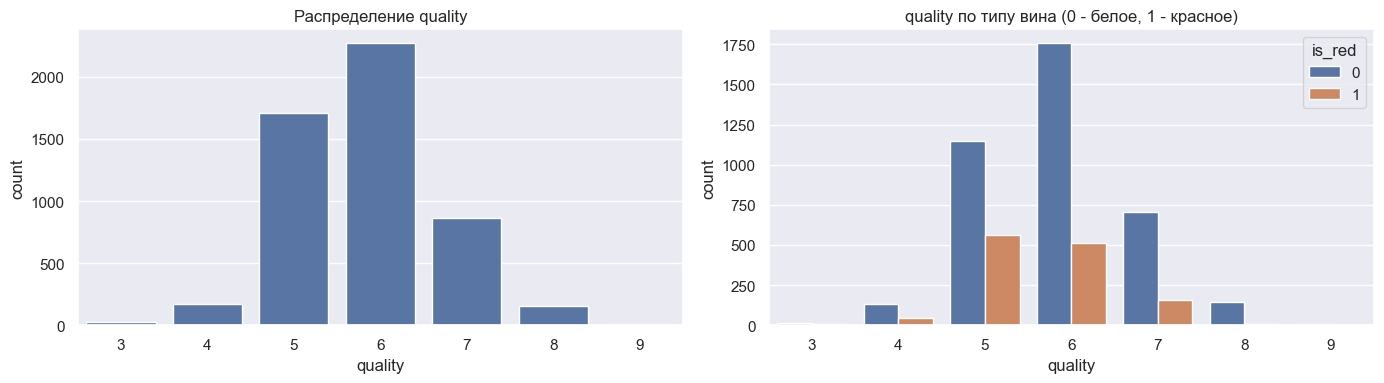

In [8]:
train = X_train.copy()
train["quality"] = y_train

fig, axs = plt.subplots(figsize=(14, 4), ncols=2)
sns.countplot(x=y_train, color="C0", ax=axs[0])
axs[0].set_title("Распределение quality")
sns.countplot(data=train, x="quality", hue="is_red", ax=axs[1])
axs[1].set_title("quality по типу вина (0 - белое, 1 - красное)")
plt.tight_layout()

print(y_train.value_counts(normalize=True).sort_index().round(3))
print("Среднее = %.3f, медиана = %.1f, std = %.3f" % (y_train.mean(), y_train.median(), y_train.std()))
print(train.groupby("is_red")["quality"].mean())

Выводы:
- Оценки сильно сконцентрированы в центре: на 5 и 6 приходится ~77% всех вин, а крайние оценки 3, 4, 8 и 9 вместе — меньше 7% (с оценкой 9 в train всего 4 вина). Значит, даже константа ≈ 5.8 будет в среднем ошибаться меньше чем на балл, а предсказывать крайние оценки моделям будет трудно: примеров мало, и функция потерь (MSE) в основном «тянет» модель к центру.
- Реально используется только шкала 3–9: оценок 0–2 и 10 нет вообще, т.е. совсем плохих и идеальных вин модель никогда не увидит.
- Белых вин в 3 раза больше, чем красных, в среднем они оценены чуть выше (5.88 против 5.62), а оценки 8–9 почти все у белых. Тип вина связан с целевой переменной, поэтому признак `is_red` оставляю.
- `quality` — целое число (порядковая шкала), а регрессия будет выдавать вещественные числа, например 5.6. Для RMSE это нормально: для вина, которое «между» 5 и 6, предсказание 5.6 в среднем даёт меньшую ошибку, чем жёсткий выбор одного из вариантов.

In [9]:
train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5197.0,7.221,1.286,4.200,6.400,7.000,7.700,15.900
volatile acidity,5197.0,0.340,0.166,0.080,0.230,0.290,0.410,1.580
citric acid,5197.0,0.318,0.146,0.000,0.240,0.310,0.390,1.660
residual sugar,5197.0,5.476,4.786,0.600,1.800,3.000,8.100,65.800
chlorides,5197.0,0.056,0.034,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,5197.0,30.548,17.647,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,5197.0,115.964,56.738,6.000,78.000,118.000,156.000,440.000
density,5197.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,5197.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,5197.0,0.532,0.147,0.230,0.430,0.510,0.600,1.950


Выводы:
- Признаки измерены в совершенно разных масштабах: `density` меняется в третьем знаке после запятой (std = 0.003), а `total sulfur dioxide` — от 6 до 440 (std ≈ 57). Для деревьев это неважно, а вот веса линейной регрессии без масштабирования сравнивать между собой будет нельзя (подробнее в части 6).
- У многих признаков длинный правый хвост и выбросы: `residual sugar` (у 75% вин до 8.1, а максимум 65.8), `chlorides`, `free sulfur dioxide` (максимум 289 при 75%-квантиле 41), `sulphates`. Выбросы я не удаляю: это реальные вина, и в тестовой выборке такие тоже могут встретиться. Деревья к выбросам в признаках устойчивы (им важен только порядок значений), а на линейную модель они могут влиять сильнее.

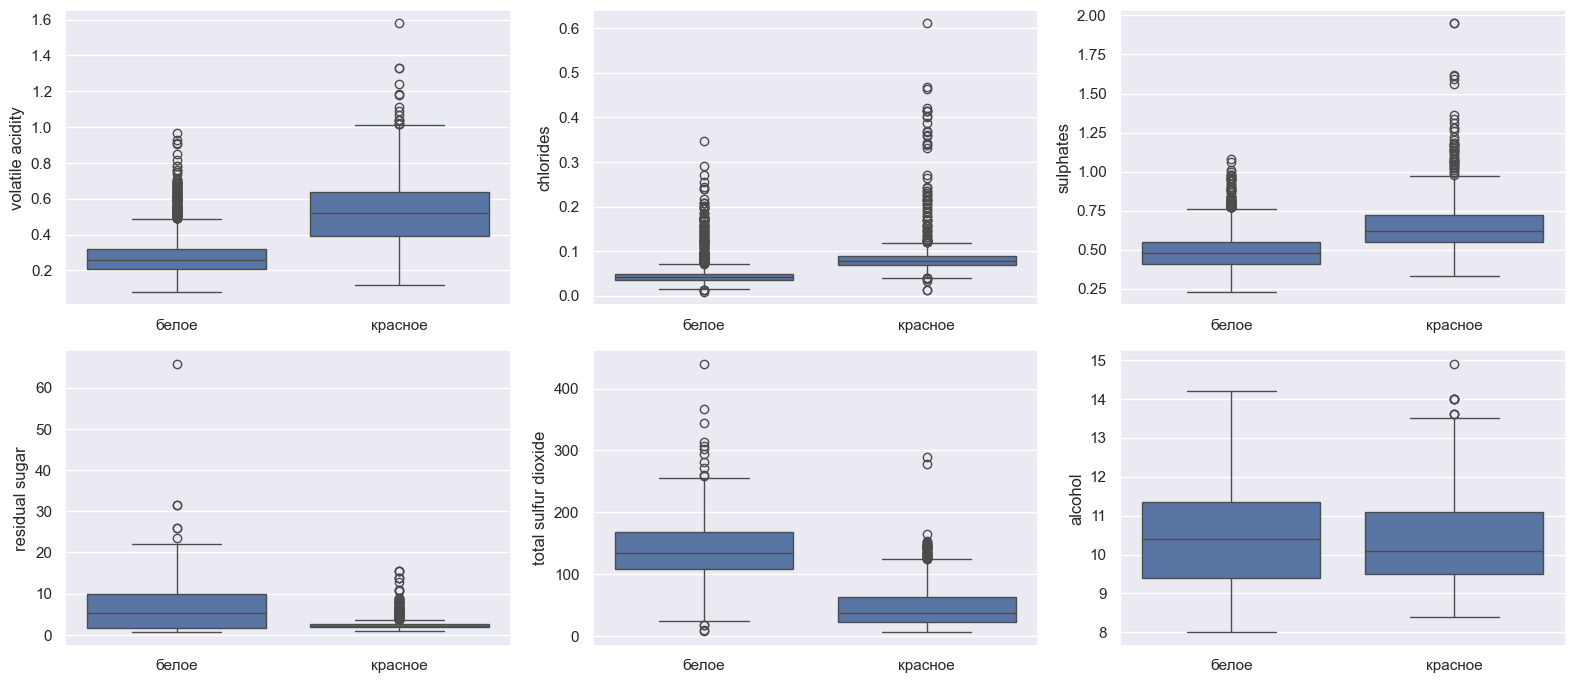

In [10]:
features = ["volatile acidity", "chlorides", "sulphates", "residual sugar", "total sulfur dioxide", "alcohol"]

fig, axs = plt.subplots(figsize=(16, 7), nrows=2, ncols=3)
for i, feature in enumerate(features):
    ax = axs[i // 3, i % 3]
    sns.boxplot(data=train, x="is_red", y=feature, ax=ax)
    ax.set_xticklabels(["белое", "красное"])
    ax.set_xlabel("")
plt.tight_layout()

Выводы: по химическому составу красное и белое вино очень сильно отличаются:
- у белого гораздо больше остаточного сахара и диоксида серы (медиана total sulfur dioxide ~135 у белого и ~40 у красного);
- у красного выше летучая кислотность, хлориды и сульфаты;
- по алкоголю они почти не отличаются.

Значит, одно и то же значение признака может значить разное для разных типов: например, total sulfur dioxide = 150 — обычное значение для белого и очень большое для красного. Поэтому признак `is_red` нужен обязательно. Линейная модель с одним общим весом на признак такие различия учесть не может (через `is_red` она может только сдвинуть предсказание на константу), а деревья могут построить разные правила для разных типов вина.

Посмотрим, какие признаки сильнее всего линейно связаны с `quality` (корреляция Пирсона). Сразу посчитаю её отдельно для белого и красного вина.

Text(0.5, 0, 'Корреляция Пирсона')

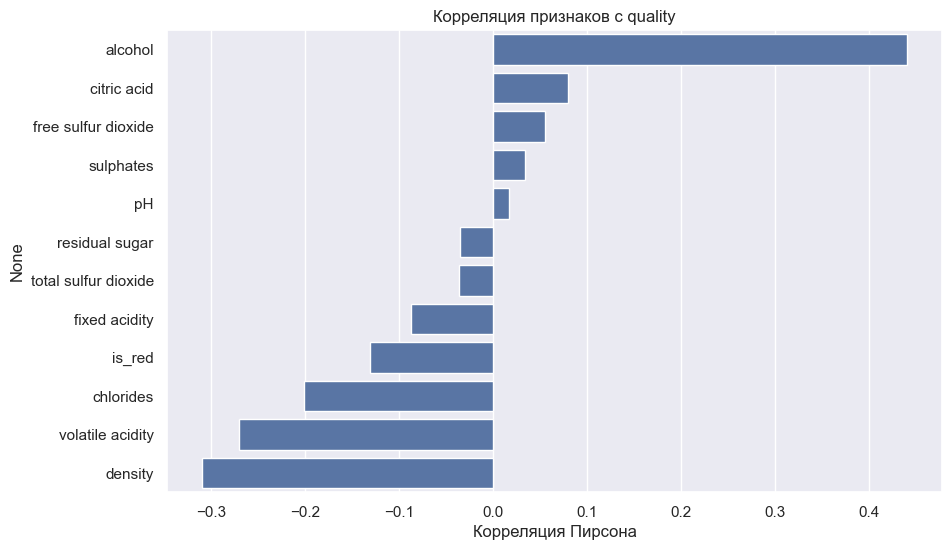

In [10]:
correlations = X_train.corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations, color="C0")
plot.figure.set_size_inches(10, 6)
plt.title("Корреляция признаков с quality")
plt.xlabel("Корреляция Пирсона")

In [11]:
is_red_train = X_train["is_red"] == 1

corr_by_type = pd.DataFrame({
    "все": X_train.drop(columns=["is_red"]).corrwith(y_train),
    "белое": X_train[~is_red_train].drop(columns=["is_red"]).corrwith(y_train[~is_red_train]),
    "красное": X_train[is_red_train].drop(columns=["is_red"]).corrwith(y_train[is_red_train]),
}).sort_values("все")
corr_by_type.round(3)

,все,белое,красное
density,-0.309,-0.304,-0.183
volatile acidity,-0.270,-0.200,-0.372
chlorides,-0.201,-0.207,-0.115
fixed acidity,-0.087,-0.117,0.114
total sulfur dioxide,-0.036,-0.182,-0.180
residual sugar,-0.035,-0.099,-0.001
pH,0.017,0.104,-0.057
sulphates,0.034,0.055,0.257
free sulfur dioxide,0.055,-0.003,-0.035
citric acid,0.080,-0.014,0.210


Выводы:
- Сильнее всего с качеством связан алкоголь (r ≈ 0.44): чем крепче вино, тем выше оценка. Это главный кандидат в признаки.
- Отрицательная связь у `density` (−0.31), `volatile acidity` (−0.27) и `chlorides` (−0.20). Летучая кислотность — это в основном уксусная кислота, при большом её количестве у вина появляется уксусный привкус, так что связь логичная.
- Остальные признаки по отдельности почти не связаны с `quality` (|r| < 0.1). Это ещё не значит, что они бесполезны: корреляция Пирсона ловит только линейную связь и только одного признака.
- Все корреляции умеренные: ни один признак сам по себе качество не определяет, поэтому сильно лучше константы одной линейной зависимостью не получится.
- Для красного и белого вина связи разные. У красного намного важнее летучая кислотность (−0.37 против −0.20), сульфаты (0.26 против 0.06) и лимонная кислота (0.21 против −0.01), у белого — плотность (−0.30 против −0.18) и хлориды. У `fixed acidity` и `pH` знак корреляции у двух типов вообще разный. В объединённом датасете эти эффекты частично смешиваются, и это ещё один аргумент за модели, которые умеют учитывать взаимодействие признаков с типом вина (деревья).

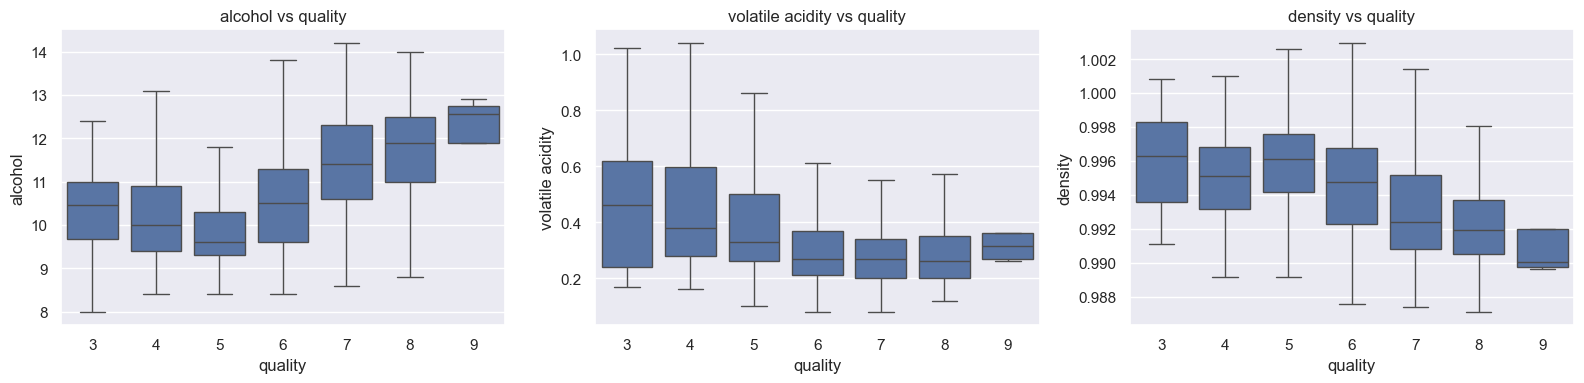

In [12]:
fig, axs = plt.subplots(figsize=(16, 4), ncols=3)
for i, feature in enumerate(["alcohol", "volatile acidity", "density"]):
    sns.boxplot(data=train, x="quality", y=feature, showfliers=False, color="C0", ax=axs[i])
    axs[i].set_title(feature + " vs quality")
plt.tight_layout()

Выводы:
- `alcohol` растёт с оценкой, но нелинейно: для оценок 3–5 медиана алкоголя примерно одинаковая (даже немного падает), а с 5 начинается уверенный рост. Линейная модель уловит общий тренд, но не этот «излом».
- `volatile acidity`, наоборот, важна в основном для плохих вин: у оценок 3–4 она заметно выше, а для 6–9 почти не меняется. Похоже на признак «дефекта»: выше какого-то порога вино получает низкую оценку. Такие пороговые зависимости хорошо ловят деревья.
- `density` падает с ростом качества, но это во многом следствие алкоголя: спирт легче воды, поэтому чем больше алкоголя, тем меньше плотность (видно на матрице корреляций ниже).

Text(0.5, 1.0, 'Корреляции между признаками')

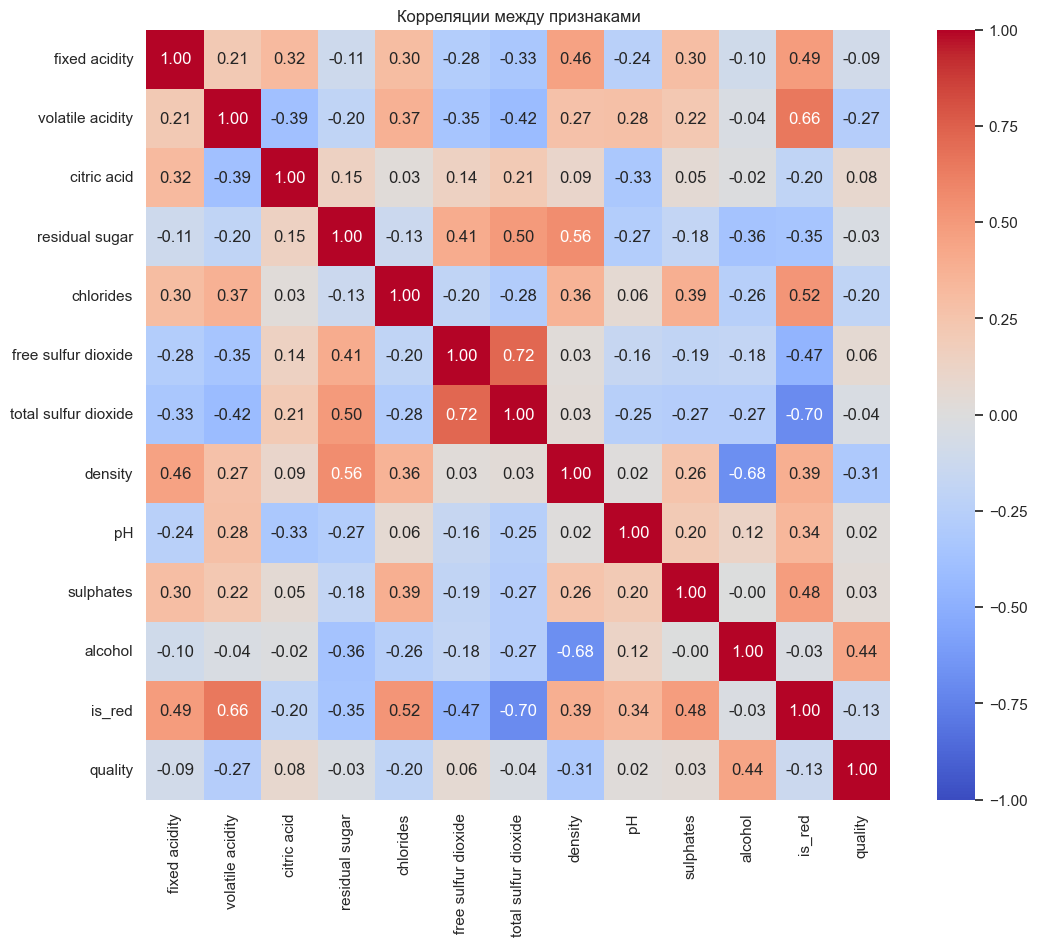

In [13]:
plt.figure(figsize=(12, 10))
sns.heatmap(train.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляции между признаками")

Выводы:
- `density` сильно связана с `alcohol` (−0.68) и `residual sugar` (0.56). Это физика: спирт легче воды, сахар тяжелее. Т.е. плотность в основном объясняется другими признаками, и её связь с качеством — во многом «отражение» алкоголя.
- `free sulfur dioxide` и `total sulfur dioxide` сильно связаны (0.72): свободный диоксид серы — это часть общего.
- `is_red` коррелирует со многими признаками (total sulfur dioxide −0.70, volatile acidity 0.66, chlorides 0.52) — это то же различие типов вина, что было видно на boxplot'ах.

Получается мультиколлинеарность. Для линейной регрессии это значит, что веса скоррелированных признаков будут неустойчивыми и их нельзя интерпретировать по отдельности (модель может дать большой отрицательный вес одному признаку и большой положительный другому, так что они друг друга компенсируют). У деревьев скоррелированные признаки будут «делить» между собой важность.

### Что я беру из анализа данных в моделирование
1. Таргет сосредоточен на 5–6, крайние оценки редкие. Ожидаю, что хуже всего модели будут предсказывать 3–4 и 8–9, это нужно проверить в анализе ошибок.
2. Главный признак — `alcohol`, дальше `density`, `volatile acidity`, `chlorides`. Ни одна связь не сильная, поэтому от линейной модели большого качества ждать не стоит.
3. Зависимости нелинейные (излом у алкоголя, порог у летучей кислотности) и разные для красного и белого вина — поэтому кроме линейной регрессии нужны модели на деревьях.
4. Признаки в разных масштабах и скоррелированы — для линейной регрессии нужно масштабирование, а её веса нужно интерпретировать осторожно.
5. Все признаки оставляю: их всего 12, пропусков нет, а слабая линейная корреляция не значит, что признак бесполезен для нелинейной модели.

# Часть 4. Метрики

$$\text{MAE} = \frac{1}{\ell}\sum_{i=1}^{\ell} |y_i - a(x_i)|, \qquad \text{RMSE} = \sqrt{\frac{1}{\ell}\sum_{i=1}^{\ell} (y_i - a(x_i))^2}$$

**Что показывает MAE.** Среднее абсолютное отклонение предсказания от правильного ответа, в тех же единицах, что и `quality` (в баллах). MAE = 0.5 значит, что в среднем модель ошибается на полбалла. Каждая ошибка входит в среднее пропорционально своей величине.

**Что показывает RMSE.** Корень из среднего квадрата ошибки. Тоже измеряется в баллах, но это не «средняя ошибка», а скорее типичный размер ошибки, в котором большие ошибки весят больше. Минимизировать RMSE — то же самое, что минимизировать MSE, а именно MSE по умолчанию оптимизируют линейная регрессия и деревья в sklearn.

**Почему RMSE сильнее реагирует на большие ошибки.** Перед усреднением ошибки возводятся в квадрат. Ошибка в 2 балла даёт вклад 4, а ошибка в 0.5 балла — 0.25, т.е. в 16 раз меньше (в MAE — только в 4 раза). Поэтому одна большая ошибка увеличивает RMSE сильнее, чем много мелких.

**Почему для одной и той же модели MAE и RMSE могут заметно различаться.** Всегда RMSE ≥ MAE (среднее квадратичное не меньше среднего арифметического), и равны они только тогда, когда все ошибки одинаковы по модулю. Чем неоднороднее ошибки, т.е. чем больше среди них редких, но крупных, тем больше разрыв. Так что по отношению RMSE/MAE можно понять, есть ли у модели «выбросы» в ошибках. В этой задаче я этого как раз жду: на типичных винах (5–6) модель будет ошибаться мало, а на редких (3, 8, 9) — сильно.

Для удобства заведу функцию, которая считает обе метрики на тесте и складывает их в общую таблицу результатов (туда же записываю CV RMSE на train).

In [14]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

results = {}

def evaluate(name, y_true, y_pred, cv_rmse=np.nan):
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    results[name] = {"RMSE": rmse, "MAE": mae, "CV RMSE": cv_rmse}
    print("%s: Test RMSE = %.4f, Test MAE = %.4f" % (name, rmse, mae))

**Схема валидации.** Все решения (гиперпараметры, выбор лучшей модели) принимаю по кросс-валидации на train: 5 фолдов с перемешиванием и фиксированным `random_state`, один и тот же объект `cv` для всех моделей, чтобы они сравнивались на одинаковых разбиениях. Тест используется только для финальной оценки.

In [15]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Часть 5. Baseline

В качестве baseline предсказываю одну константу для всех объектов. Какую константу брать, зависит от метрики:
- для MSE/RMSE оптимальная константа — **среднее** значение таргета: если продифференцировать $\sum_i (y_i - c)^2$ по $c$ и приравнять к нулю, получится $c = \frac{1}{\ell}\sum_i y_i$;
- для MAE оптимальная константа — **медиана**.

Основная метрика — RMSE, поэтому baseline = среднее `quality` по **train** (тест для подсчёта константы не используется).

In [16]:
from sklearn.dummy import DummyRegressor

best_constant = y_train.mean()
print("Best constant (mean of y_train) = %.4f" % best_constant)

cv_scores = cross_val_score(DummyRegressor(strategy="mean"), X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print("Mean CV RMSE = %.4f" % np.mean(-cv_scores))

y_pred_baseline = best_constant * np.ones(y_test.shape)
evaluate("Baseline", y_test, y_pred_baseline, np.mean(-cv_scores))

# для сравнения: медиана - оптимальная константа для MAE
median_constant = y_train.median()
y_pred_median = median_constant * np.ones(y_test.shape)
print("Median constant = %.1f: Test RMSE = %.4f, Test MAE = %.4f" % (median_constant, root_mean_squared_error(y_test, y_pred_median), mean_absolute_error(y_test, y_pred_median)))

Best constant (mean of y_train) = 5.8182
Mean CV RMSE = 0.8732
Baseline: Test RMSE = 0.8738, Test MAE = 0.6861
Median constant = 6.0: Test RMSE = 0.8923, Test MAE = 0.6377


Вывод: baseline даёт на тесте RMSE = 0.874 — почти ровно стандартное отклонение `quality` (0.873). Так и должно быть: RMSE константы, равной среднему, и есть std таргета. Значит, полезная модель должна давать RMSE заметно меньше 0.87, а порог 0.70 — это на 20% лучше константы.

Медиана (6) даёт RMSE хуже (0.892), но MAE лучше (0.638 против 0.686). Это подтверждает, что для разных метрик оптимальны разные константы. В таблицу записываю среднее, т.к. основная метрика — RMSE.

# Часть 6. Линейная регрессия

Строю `Pipeline` из `StandardScaler` и `LinearRegression`. Pipeline нужен, чтобы при кросс-валидации scaler обучался (считал среднее и std) только на обучающих фолдах, а не на всём train, иначе в обучение протекает информация из валидационного фолда.

Требуется ли масштабирование? На качество обычной линейной регрессии (без регуляризации) масштабирование не влияет: если признак умножить на число, вес просто поделится на это число, и предсказания останутся теми же. Но оно сильно влияет на **интерпретацию коэффициентов**, это разберу ниже.

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

linear_pipeline = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", LinearRegression())
])

cv_scores = cross_val_score(linear_pipeline, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print("Cross validation scores:\n\t", "\n\t".join("%.4f" % x for x in -cv_scores))
print("Mean CV RMSE = %.4f" % np.mean(-cv_scores))

linear_pipeline.fit(X_train, y_train)
y_pred_linear = linear_pipeline.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, linear_pipeline.predict(X_train)))
evaluate("Linear Regression", y_test, y_pred_linear, np.mean(-cv_scores))

Cross validation scores:
	 0.7346
	0.7194
	0.7580
	0.7454
	0.7309
Mean CV RMSE = 0.7377
Train RMSE = 0.7337
Linear Regression: Test RMSE = 0.7280, Test MAE = 0.5678


Вывод: линейная регрессия даёт RMSE = 0.728 на тесте (CV RMSE = 0.738). Это на 17% лучше baseline (0.874), т.е. модель действительно извлекает из признаков полезную информацию, но порог 0.70 не проходит.

Ошибка на train (0.734) почти такая же, как на CV и на тесте, значит переобучения нет. Наоборот, модель **недообучена**: она слишком простая для этих данных. После анализа данных это ожидаемо: зависимости нелинейные (излом у алкоголя, порог у летучей кислотности) и различаются для красного и белого вина, а линейная модель может только сложить признаки с весами. Разброс по фолдам небольшой (0.72–0.76), так что оценка стабильная.

In [18]:
def show_weights(features, weights, scales, title):
    fig, axs = plt.subplots(figsize=(14, 5), ncols=2)
    sorted_weights = sorted(zip(weights, features, scales), reverse=True)
    weights = [x[0] for x in sorted_weights]
    features = [x[1] for x in sorted_weights]
    scales = [x[2] for x in sorted_weights]
    sns.barplot(y=features, x=weights, color="C0", ax=axs[0])
    axs[0].set_xlabel("Weight")
    axs[0].set_title(title)
    sns.barplot(y=features, x=scales, color="C1", ax=axs[1])
    axs[1].set_xlabel("Scale (std)")
    plt.tight_layout()

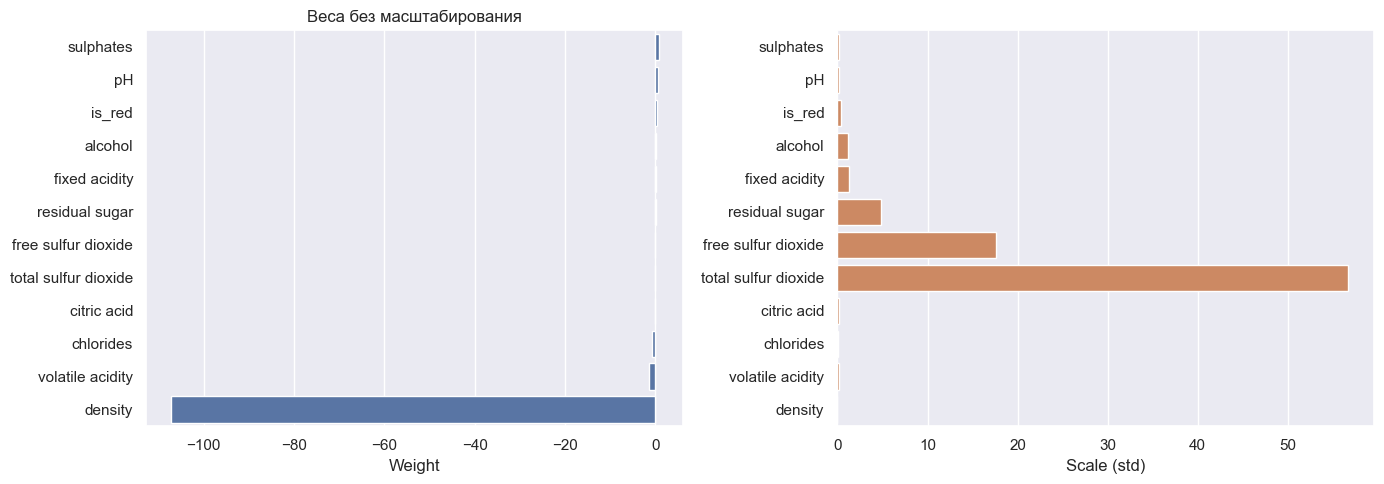

In [19]:
raw_model = LinearRegression().fit(X_train, y_train)
show_weights(X_train.columns, raw_model.coef_, X_train.std(), "Веса без масштабирования")

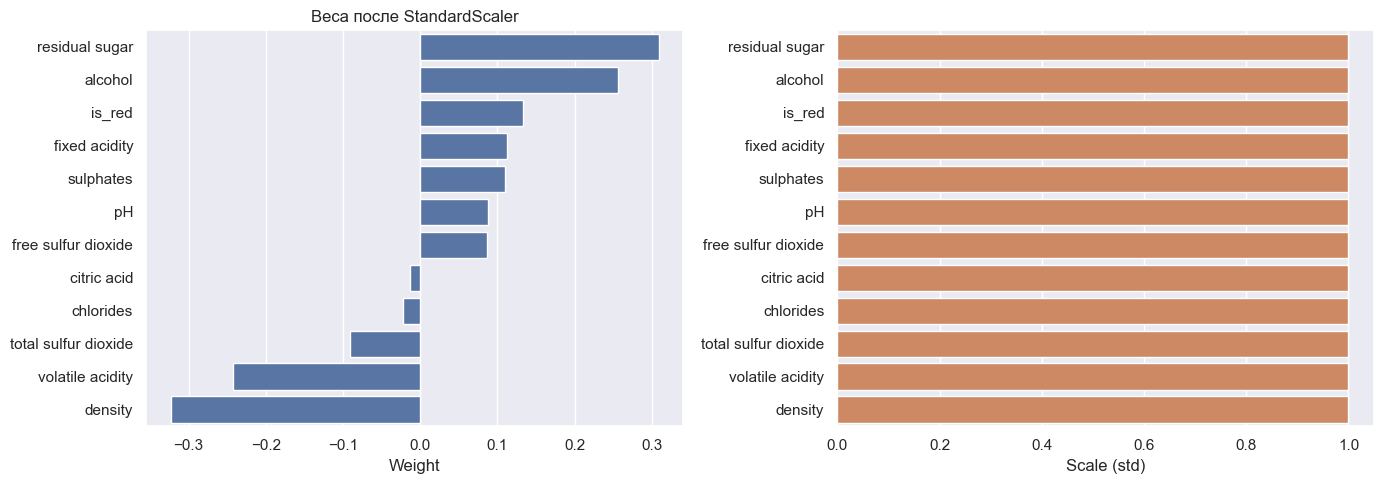

In [20]:
scaler = linear_pipeline.named_steps["scaling"]
linear_model = linear_pipeline.named_steps["regression"]
X_train_scaled = scaler.transform(X_train)

show_weights(X_train.columns, linear_model.coef_, X_train_scaled.std(axis=0), "Веса после StandardScaler")

In [21]:
coefs = pd.DataFrame({
    "вес без масштабирования": raw_model.coef_,
    "std признака": scaler.scale_,
    "вес после масштабирования": linear_model.coef_,
}, index=X_train.columns)
coefs["|вес после масштабирования|"] = coefs["вес после масштабирования"].abs()
coefs.sort_values("|вес после масштабирования|", ascending=False).round(4)

,вес без масштабирования,std признака,вес после масштабирования,|вес после масштабирования|
density,-107.2543,0.0030,-0.3230,0.3230
residual sugar,0.0645,4.7851,0.3086,0.3086
alcohol,0.2152,1.1888,0.2558,0.2558
volatile acidity,-1.4620,0.1657,-0.2423,0.2423
is_red,0.3089,0.4323,0.1335,0.1335
fixed acidity,0.0872,1.2860,0.1121,0.1121
sulphates,0.7447,0.1468,0.1093,0.1093
total sulfur dioxide,-0.0016,56.7329,-0.0909,0.0909
pH,0.5483,0.1607,0.0881,0.0881
free sulfur dioxide,0.0049,17.6453,0.0861,0.0861


Выводы по коэффициентам:
- **Без масштабирования** сравнивать веса нельзя. У `density` вес ≈ −107, а у остальных признаков — порядка 0.001–1. Но это не значит, что плотность в 100 раз важнее: она меняется в пределах ~0.003, поэтому вес огромный, а реальный вклад в предсказание (вес × std признака) ≈ −107 × 0.003 ≈ −0.32 балла. И наоборот, у `total sulfur dioxide` вес всего −0.0016, но сам признак меняется на десятки единиц.
- **После StandardScaler** вес показывает, на сколько баллов меняется предсказание, если признак увеличить на одно стандартное отклонение (при остальных фиксированных). В таблице видно, что вес после масштабирования = вес до × std признака. Теперь веса можно сравнивать между собой.
- Наибольшее влияние в линейной модели у `density` (−0.32), `residual sugar` (+0.31), `alcohol` (+0.26) и `volatile acidity` (−0.24), дальше идут `is_red`, `fixed acidity`, `sulphates`.

Здесь же видна мультиколлинеарность, найденная в EDA. `residual sugar` получил большой **положительный** вес (+0.31), хотя его корреляция с качеством около нуля (−0.03), а у `density` вес по модулю больше, чем у алкоголя. Дело в том, что плотность почти определяется алкоголем и сахаром, и модель использует эти три признака в комбинации: «больше сахара при той же плотности» фактически означает «больше алкоголя». Поэтому эти веса нельзя читать как независимый эффект каждого признака, они сильно зависят от того, какие ещё признаки есть в модели. Похожая история с `is_red`: вес положительный (+0.13), хотя красные вина в среднем оценены ниже. То есть при одинаковой химии красное предсказывается даже выше, а низкие оценки красных объясняются их более высокой летучей кислотностью и т.п.

Надёжные выводы, которые совпадают с EDA: алкоголь повышает предсказание, летучая кислотность понижает.

У `LinearRegression` нет гиперпараметров, которые можно подбирать. Поэтому проверю, не поможет ли регуляризация: подберу `alpha` у `Ridge` случайным поиском по логарифмической шкале с той же кросс-валидацией.

Best alpha = 17.7188
Best CV RMSE = 0.7376


Text(0.5, 1.0, 'Ridge: подбор alpha')

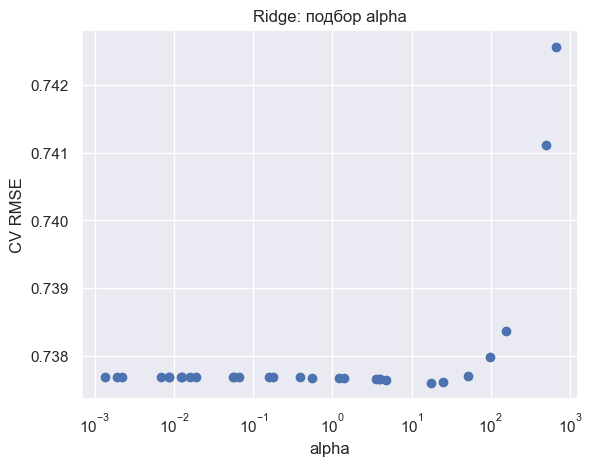

In [22]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

ridge_pipeline = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", Ridge())
])

ridge_searcher = RandomizedSearchCV(
    ridge_pipeline,
    {"regression__alpha": loguniform(1e-3, 1e3)},
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE
)
ridge_searcher.fit(X_train, y_train)

print("Best alpha = %.4f" % ridge_searcher.best_params_["regression__alpha"])
print("Best CV RMSE = %.4f" % -ridge_searcher.best_score_)

alphas = ridge_searcher.cv_results_["param_regression__alpha"].data.astype(float)
plt.scatter(alphas, -ridge_searcher.cv_results_["mean_test_score"])
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("CV RMSE")
plt.title("Ridge: подбор alpha")

Вывод: регуляризация ничего не даёт. CV RMSE почти не меняется при alpha от 0.001 до ~50 (лучшее значение 0.7376 против 0.7377 у обычной регрессии), а при большом alpha становится только хуже. Это логично: признаков всего 12, объектов больше 5000, и у модели нет проблемы с переобучением (train ≈ CV), а Ridge борется именно с переобучением. Проблема линейной модели — недообучение, и регуляризацией её не исправить. Поэтому в итоговую таблицу записываю обычную `LinearRegression`, а Ridge на тесте не проверяю (тест не используется для выбора).

# Часть 7. Random Forest

Случайный лес — это усреднение многих глубоких решающих деревьев, каждое из которых обучено на бутстрап-выборке и при каждом разбиении выбирает из случайного подмножества признаков. Деревья умеют находить нелинейные и пороговые зависимости и взаимодействия признаков (например, разные правила для красного и белого вина), а усреднение уменьшает разброс отдельных деревьев.

Масштабирование для деревьев не нужно: разбиение — это порог вида «признак < t», и при монотонном преобразовании признака меняется только значение порога, а не само разбиение.

Гиперпараметры подбираю через `RandomizedSearchCV` на тех же 5 фолдах:
- `n_estimators` — число деревьев (больше — стабильнее, но дольше);
- `max_depth`, `min_samples_split`, `min_samples_leaf` — ограничивают сложность каждого дерева;
- `max_features` — сколько признаков рассматривать при каждом разбиении (меньше — деревья разнообразнее).

Почему случайный поиск, а не полный перебор по сетке: параметров 5, и полная сетка из всех комбинаций — это тысячи обучений леса. Случайный поиск за фиксированный бюджет (30 комбинаций) пробует больше разных значений каждого параметра, а обычно на качество сильно влияют лишь 1–2 параметра, поэтому этого хватает.

In [23]:
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import randint

rf_params = {
    "n_estimators": randint(100, 600),
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_split": randint(2, 11),
    "min_samples_leaf": randint(1, 6),
    "max_features": ["sqrt", 0.3, 0.5, 0.7, 1.0],
}

rf_searcher = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE),
    rf_params,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_searcher.fit(X_train, y_train)

print("Best params:", rf_searcher.best_params_)
print("Best CV RMSE = %.4f" % -rf_searcher.best_score_)

Best params: {'max_depth': 30, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 149}
Best CV RMSE = 0.6212


In [24]:
rf_cv_results = pd.DataFrame(rf_searcher.cv_results_)
rf_cv_results["CV RMSE"] = -rf_cv_results["mean_test_score"]
rf_cv_results = rf_cv_results.sort_values("CV RMSE")
rf_cv_results[["param_n_estimators", "param_max_depth", "param_min_samples_split", "param_min_samples_leaf", "param_max_features", "CV RMSE", "std_test_score"]].head(10)

,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_max_features,CV RMSE,std_test_score
11,149,30,5,1,0.5,0.621183,0.012992
13,301,30,3,2,0.3,0.624597,0.011788
23,200,15,4,1,0.5,0.625087,0.010988
12,409,20,5,2,0.3,0.626313,0.011944
6,463,15,4,2,0.5,0.626442,0.011049
21,506,20,8,1,0.3,0.627165,0.011398
8,188,30,5,2,sqrt,0.627438,0.011647
19,589,15,6,1,0.5,0.627601,0.011237
17,108,30,8,1,sqrt,0.629719,0.012144
25,162,15,4,2,sqrt,0.630042,0.012953


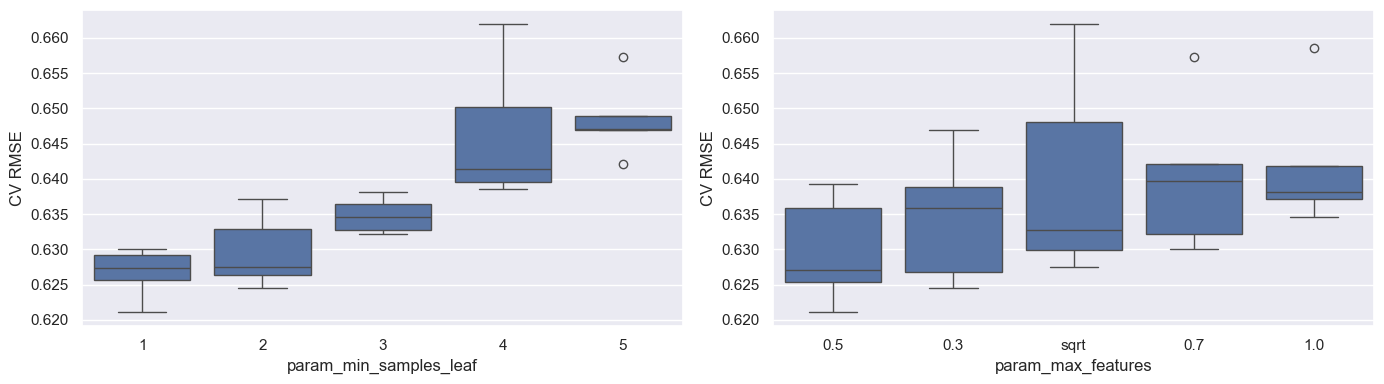

In [25]:
fig, axs = plt.subplots(figsize=(14, 4), ncols=2)
sns.boxplot(data=rf_cv_results, x="param_min_samples_leaf", y="CV RMSE", color="C0", ax=axs[0])
sns.boxplot(data=rf_cv_results, x="param_max_features", y="CV RMSE", color="C0", ax=axs[1])
plt.tight_layout()

In [26]:
rf_model = rf_searcher.best_estimator_
y_pred_rf = rf_model.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, rf_model.predict(X_train)))
evaluate("Random Forest", y_test, y_pred_rf, -rf_searcher.best_score_)

Train RMSE = 0.2711
Random Forest: Test RMSE = 0.6010, Test MAE = 0.4334


Вывод:
- Лучшая комбинация: глубокие деревья (`max_depth=30`, `min_samples_leaf=1`), `max_features=0.5`, ~150 деревьев. CV RMSE = 0.621, на тесте RMSE = 0.601, MAE = 0.433. Порог 0.70 пройден с запасом, ошибка на 31% меньше, чем у baseline.
- По графикам видно, что сильнее всего на качество влияет `min_samples_leaf`: чем меньше листья (т.е. чем точнее дерево подстраивается под отдельные объекты), тем лучше. `max_features` 0.3–0.5 в среднем немного лучше, чем все признаки (1.0): деревья получаются разнообразнее, и усреднение работает лучше.
- RMSE на train = 0.27, сильно меньше, чем на тесте. Для случайного леса это нормально (глубокие деревья почти запоминают train). Важно, что CV и тест близки друг к другу, т.е. оценка честная. То, что выгоднее всего «запоминать» отдельные объекты, отчасти связано с дубликатами: у заметной части объектов валидационного фолда есть точная копия в обучающих фолдах. Это проверю в части 11.

Text(0.5, 0, 'Importance')

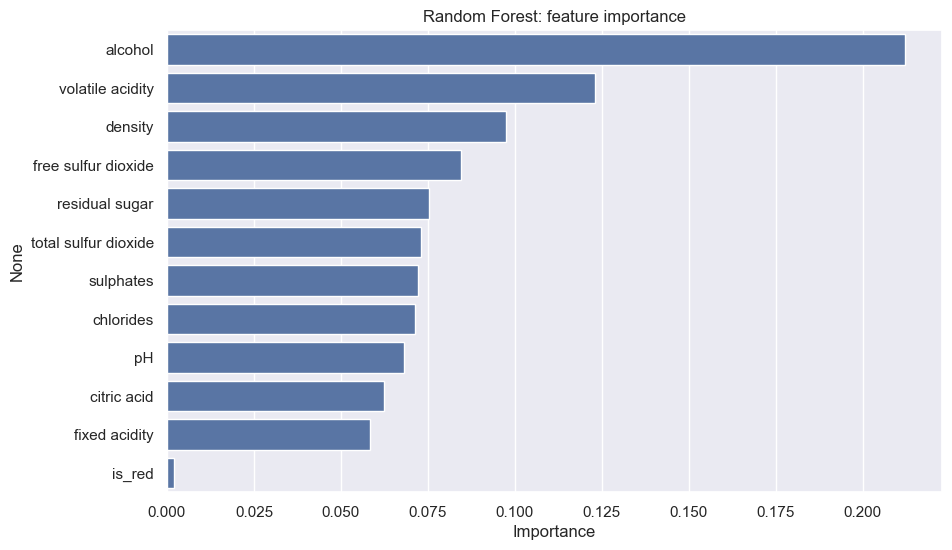

In [27]:
rf_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plot = sns.barplot(y=rf_importances.index, x=rf_importances, color="C0")
plot.figure.set_size_inches(10, 6)
plt.title("Random Forest: feature importance")
plt.xlabel("Importance")

`feature_importances_` у случайного леса (impurity-based, MDI) показывает, насколько в сумме уменьшается MSE за счёт разбиений по этому признаку во всех деревьях (нормировано так, что сумма = 1).

Выводы:
- Самый важный признак — `alcohol` (≈0.21), с большим отрывом. Дальше идут `volatile acidity` (≈0.12) и `density` (≈0.10). Это совпадает с EDA: ровно у этих признаков самая сильная корреляция с качеством.
- Остальные признаки идут плотной группой (0.06–0.085), и тут уже есть отличия от корреляций и от линейной регрессии. Например, `free sulfur dioxide` у леса на 4-м месте, хотя его линейная корреляция с качеством около нуля (0.06). Значит, связь с ним нелинейная или проявляется только в сочетании с другими признаками, и лес её находит, а линейная модель — нет.
- `density` и `residual sugar`, у которых в линейной регрессии были самые большие веса, у леса на 3-м и 5-м месте. Это подтверждает, что их большие веса в LR — во многом артефакт мультиколлинеарности: лес может просто взять алкоголь напрямую.
- `is_red` на последнем месте с почти нулевой важностью, хотя в EDA тип вина сильно влиял на распределения признаков. Дело в том, что тип вина почти однозначно восстанавливается по другим признакам (total sulfur dioxide, volatile acidity, chlorides), и деревьям не нужно отдельное разбиение по `is_red`. Информация о типе в модели есть, просто она «размазана» по другим признакам. Т.е. низкая важность признака ещё не значит, что стоящая за ним информация не важна.
- Надо помнить, что MDI считается по train и завышает важность непрерывных признаков с большим числом уникальных значений (у бинарного `is_red` вообще только одно возможное разбиение). Поэтому в части 10 дополнительно проверю важность другим способом.

# Часть 8. Gradient Boosting

Градиентный бустинг строит деревья последовательно: каждое следующее дерево обучается исправлять ошибки уже построенного ансамбля (приближает антиградиент функции потерь, для MSE это просто остатки), и его вклад умножается на `learning_rate`. В отличие от леса, где деревья независимые и усредняются, в бустинге деревья зависят друг от друга, и качество растёт за счёт их количества.

Подбираю через `RandomizedSearchCV` на тех же фолдах:
- `n_estimators` и `learning_rate` связаны: чем меньше шаг, тем больше нужно деревьев (поэтому `learning_rate` беру по логарифмической шкале);
- `max_depth`, `min_samples_leaf` — сложность одного дерева;
- `subsample` — доля объектов для обучения каждого дерева (стохастический бустинг, уменьшает переобучение);
- `max_features` — как у леса.

In [28]:
from sklearn.ensemble import GradientBoostingRegressor
from scipy.stats import uniform

gb_params = {
    "n_estimators": randint(100, 1200),
    "learning_rate": loguniform(0.01, 0.2),
    "max_depth": randint(2, 11),
    "min_samples_leaf": randint(1, 20),
    "subsample": uniform(0.6, 0.4),
    "max_features": [None, "sqrt", 0.5, 0.7],
}

gb_searcher = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    gb_params,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
gb_searcher.fit(X_train, y_train)

print("Best params:", gb_searcher.best_params_)
print("Best CV RMSE = %.4f" % -gb_searcher.best_score_)

Best params: {'learning_rate': np.float64(0.011900590783184251), 'max_depth': 9, 'max_features': None, 'min_samples_leaf': 4, 'n_estimators': 971, 'subsample': np.float64(0.8832290311184181)}
Best CV RMSE = 0.6190


In [29]:
gb_cv_results = pd.DataFrame(gb_searcher.cv_results_)
gb_cv_results["CV RMSE"] = -gb_cv_results["mean_test_score"]
gb_cv_results = gb_cv_results.sort_values("CV RMSE")
gb_cv_results[["param_n_estimators", "param_learning_rate", "param_max_depth", "param_min_samples_leaf", "param_subsample", "param_max_features", "CV RMSE", "std_test_score"]].head(10)

,param_n_estimators,param_learning_rate,param_max_depth,param_min_samples_leaf,param_subsample,param_max_features,CV RMSE,std_test_score
1,971,0.011901,9,4,0.883229,None,0.619041,0.011185
12,747,0.016407,10,9,0.602209,0.5,0.622887,0.013163
23,809,0.019795,10,13,0.804299,0.7,0.623063,0.010411
29,983,0.020657,7,5,0.993369,0.7,0.626567,0.010975
14,1151,0.012483,8,9,0.945241,sqrt,0.627389,0.010849
11,1164,0.057994,10,13,0.718509,0.7,0.629595,0.016806
18,306,0.053733,8,9,0.771016,0.5,0.630604,0.011832
10,437,0.047602,9,16,0.815877,None,0.631036,0.012845
0,221,0.030711,9,7,0.662398,None,0.631918,0.013288
20,848,0.080332,6,7,0.815936,0.5,0.634186,0.014000


In [30]:
gb_model = gb_searcher.best_estimator_
y_pred_gb = gb_model.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, gb_model.predict(X_train)))
evaluate("Gradient Boosting", y_test, y_pred_gb, -gb_searcher.best_score_)

Train RMSE = 0.1717
Gradient Boosting: Test RMSE = 0.5920, Test MAE = 0.4162


Вывод:
- Лучшая комбинация: маленький шаг (`learning_rate` ≈ 0.012) и много деревьев (971), довольно глубокие деревья (`max_depth=9`), `subsample` ≈ 0.88. Маленький шаг и много деревьев — типичная пара: каждое дерево вносит небольшую поправку, и ансамбль меньше переобучается. Сначала я брал `max_depth` до 7, и лучшее значение упиралось в границу диапазона, поэтому расширил диапазон до 10. Сейчас лучшее значение (9) внутри диапазона. `learning_rate` близок к нижней границе, но это компенсируется числом деревьев (важно в основном их сочетание), так что дальше не расширял.
- CV RMSE = 0.619, на тесте RMSE = 0.592, MAE = 0.416 — немного лучше случайного леса по обеим метрикам и на CV, и на тесте.
- RMSE на train = 0.17, т.е. бустинг подстроился под обучающие данные ещё сильнее, чем лес. То, что выгоднее всего глубокие деревья, — снова признак того, что модели выгодно «запоминать» конкретные объекты (см. часть 11 про дубликаты).

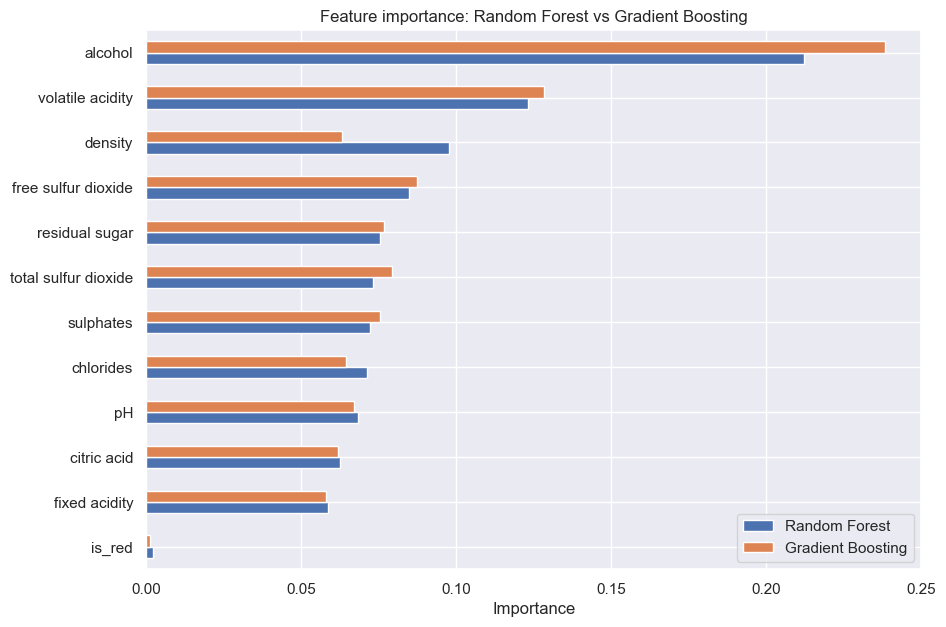

In [31]:
gb_importances = pd.Series(gb_model.feature_importances_, index=X_train.columns)

importances = pd.DataFrame({"Random Forest": rf_importances, "Gradient Boosting": gb_importances}).sort_values("Random Forest")
importances.plot(kind="barh", figsize=(10, 7))
plt.title("Feature importance: Random Forest vs Gradient Boosting")
plt.xlabel("Importance")
plt.legend(loc="lower right")

Выводы (сравнение RF и GB):
- Топ-2 у обеих моделей одинаковый: `alcohol` (у бустинга даже больше — 0.24) и `volatile acidity` (≈0.13). Внизу у обеих тоже одно и то же: `is_red`, `fixed acidity`, `citric acid`.
- Главное отличие — `density`: у леса это 3-й признак (≈0.10), а у бустинга только 9-й (≈0.06), зато у бустинга выше `free sulfur dioxide` и `total sulfur dioxide`. Объяснение — снова корреляция плотности с алкоголем. В лесу при каждом разбиении доступна только половина признаков (`max_features=0.5`), и когда `alcohol` не попал в это подмножество, дерево берёт его «заместителя» `density`. В бустинге `max_features=None` (доступны все признаки), и каждое следующее дерево исправляет остатки предыдущих: информацию об алкоголе уже забрали первые деревья, и плотность почти ничего нового не добавляет.
- В целом у обеих моделей картина согласуется с EDA (алкоголь и летучая кислотность — главные), но, в отличие от корреляций, у деревьев заметную роль играют диоксид серы и сульфаты, у которых линейная связь с качеством слабая.

# Часть 9. Честное сравнение моделей

Условия для всех моделей одинаковые:
- одни и те же признаки (11 измерений + `is_red`) и одни и те же данные: train и test получены одним разбиением в части 2;
- гиперпараметры подобраны на одних и тех же фолдах `cv`;
- все метрики посчитаны на одном и том же test.

Единственное отличие в обработке — `StandardScaler` внутри пайплайна линейной регрессии. На её предсказания он не влияет и нужен только для интерпретации весов. Деревьям масштабирование не нужно: их предсказания от него не изменились бы.

In [32]:
results_df = pd.DataFrame(results).T
results_df["Лучше baseline"] = results_df["RMSE"] < results_df.loc["Baseline", "RMSE"]
results_df["RMSE < 0.70"] = results_df["RMSE"] < 0.70
results_df.round(4)

,RMSE,MAE,CV RMSE,Лучше baseline,RMSE < 0.70
Baseline,0.8738,0.6861,0.8732,False,False
Linear Regression,0.7280,0.5678,0.7377,True,False
Random Forest,0.6010,0.4334,0.6212,True,True
Gradient Boosting,0.5920,0.4162,0.6190,True,True


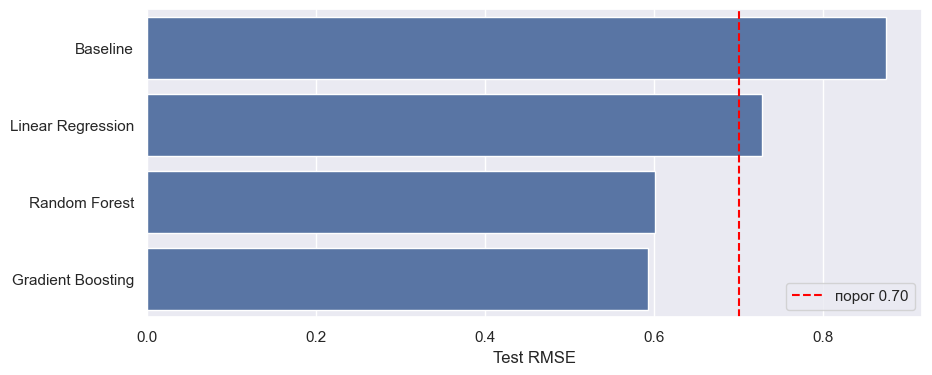

In [33]:
plot = sns.barplot(y=results_df.index, x=results_df["RMSE"], color="C0")
plot.figure.set_size_inches(10, 4)
plt.axvline(0.70, color="red", linestyle="--", label="порог 0.70")
plt.xlabel("Test RMSE")
plt.ylabel("")
plt.legend()

Выводы:
- **Все три модели превзошли baseline** (0.874): линейная регрессия — на 17% (0.728), случайный лес — на 31% (0.601), бустинг — на 32% (0.592). Т.е. модели действительно извлекают информацию из признаков, а не просто выдают среднее.
- **Порог 0.70 проходят только модели на деревьях**, линейная регрессия его не проходит.
- Порядок моделей по CV и по тесту одинаковый, и CV RMSE близок к тестовому. Значит, выбор по кросс-валидации работает, и тест не «подогнан».

Почему так получилось:
- **Linear Regression** хуже всех, потому что недообучена: она может описать только сумму признаков с весами. А в данных, как показал EDA, связи нелинейные (у алкоголя излом на оценке 5, у летучей кислотности пороговый эффект), и один и тот же признак работает по-разному для красного и белого вина. Train RMSE ≈ test RMSE — модели просто не хватает гибкости.
- **Random Forest и Gradient Boosting** состоят из деревьев, которые сами находят пороги и взаимодействия признаков (например, «если вино красное и летучая кислотность > 0.7, то оценка низкая»). Поэтому им хватает тех же 12 признаков без ручного feature engineering.
- **Бустинг чуть лучше леса** (0.592 против 0.601, на CV 0.619 против 0.621), но разница маленькая — на CV она меньше разброса по фолдам (std ≈ 0.011), так что считать её значимой нельзя. Лес уменьшает разброс, усредняя независимые глубокие деревья, а бустинг уменьшает смещение, последовательно исправляя ошибки. При шумном таргете (оценка эксперта субъективна) оба подхода упираются примерно в один уровень. В части 11 видно, что преимущество бустинга появляется в основном на винах, у которых есть копия в train.
- **MAE у всех моделей заметно меньше RMSE** (у бустинга 0.416 против 0.592): большинство вин предсказывается точно, а RMSE раздувают редкие крупные ошибки. Это разберу в анализе ошибок.

# Часть 10. Feature importance: сравнение моделей

Сравнивать напрямую веса линейной регрессии и `feature_importances_` деревьев некорректно — это разные величины. К тому же impurity-based importance у деревьев считается по train и завышает важность признаков с большим числом уникальных значений.

Поэтому для всех трёх моделей дополнительно посчитаю **permutation importance**: случайно перемешиваю значения одного признака в тестовой выборке и смотрю, насколько вырастет RMSE. Чем сильнее растёт ошибка, тем больше модель полагается на этот признак. Это одна и та же величина (прирост RMSE в баллах) для любой модели, поэтому модели можно сравнивать между собой. Считаю на тесте, потому что модели уже обучены и зафиксированы, и по этим результатам ничего не выбирается — это только интерпретация.

Text(0.5, 0, 'Прирост RMSE')

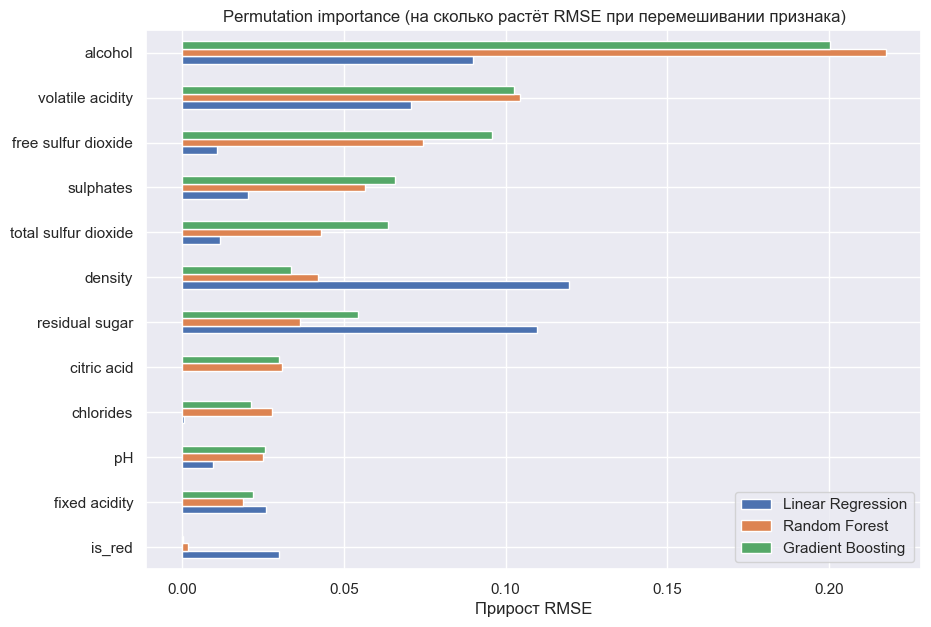

In [34]:
from sklearn.inspection import permutation_importance

models = {"Linear Regression": linear_pipeline, "Random Forest": rf_model, "Gradient Boosting": gb_model}

perm_importances = {}
for name, model in models.items():
    perm = permutation_importance(model, X_test, y_test, scoring="neg_root_mean_squared_error", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    perm_importances[name] = pd.Series(perm.importances_mean, index=X_test.columns)

perm_importances = pd.DataFrame(perm_importances).sort_values("Random Forest")
perm_importances.plot(kind="barh", figsize=(10, 7))
plt.title("Permutation importance (на сколько растёт RMSE при перемешивании признака)")
plt.xlabel("Прирост RMSE")

In [35]:
ranks = pd.DataFrame({
    "|corr| с quality": X_train.corrwith(y_train).abs(),
    "|вес| LR": coefs["|вес после масштабирования|"],
    "RF importance": rf_importances,
    "GB importance": gb_importances,
    "perm LR": perm_importances["Linear Regression"],
    "perm RF": perm_importances["Random Forest"],
    "perm GB": perm_importances["Gradient Boosting"],
}).rank(ascending=False).astype(int)
ranks.sort_values("perm RF")

,|corr| с quality,|вес| LR,RF importance,GB importance,perm LR,perm RF,perm GB
alcohol,1,3,1,1,3,1,1
volatile acidity,3,4,2,2,4,2,2
free sulfur dioxide,8,10,4,3,9,3,3
sulphates,11,7,7,6,7,4,4
total sulfur dioxide,9,8,6,4,8,5,5
density,2,1,3,9,1,6,7
residual sugar,10,2,5,5,2,7,6
citric acid,7,12,10,10,12,8,8
chlorides,4,11,8,8,11,9,11
pH,12,9,9,7,10,10,9


Выводы:
- **Модели на деревьях согласны между собой**: по permutation importance у RF и GB одинаковый топ-5 — `alcohol`, `volatile acidity`, `free sulfur dioxide`, `sulphates`, `total sulfur dioxide`. Алкоголь с большим отрывом самый важный: если его перемешать, RMSE вырастает на ~0.2 балла.
- **Линейная регрессия опирается на другое**: `density` и `residual sugar` у неё важнее алкоголя. Это следствие мультиколлинеарности: модель собрала из алкоголя, сахара и плотности комбинацию с большими весами, и если перемешать любой из них, комбинация ломается. Деревья берут алкоголь напрямую.
- **`free sulfur dioxide` и `sulphates`** важны для деревьев, но почти не важны для LR и слабо коррелируют с качеством. Значит, у них нелинейная связь или связь, которая зависит от типа вина (у красного корреляция сульфатов с качеством 0.26, у белого почти ноль). Деревья это ловят, а корреляция Пирсона и линейная модель — нет.
- **`is_red`** у деревьев почти не важен, а у LR в топ-5: деревья восстанавливают тип вина по другим признакам, а линейной модели нужен отдельный сдвиг для красного.
- **Сравнение с EDA**: признаки с самой сильной корреляцией (алкоголь, летучая кислотность) — главные и для всех моделей. А вот `density` и `chlorides`, которые по корреляции были на 2-м и 4-м местах, для деревьев оказались второстепенными: их связь с качеством идёт в основном «через» алкоголь и тип вина. MDI и permutation importance у деревьев в целом совпадают, но MDI сильнее «размазан» по признакам и завышает `density`.

**Можно ли на основании feature importance утверждать, что изменение признака является причиной изменения качества вина?**

Нет. Feature importance показывает только то, насколько **модель** использует признак для предсказания, т.е. насколько он статистически связан с оценкой в этих данных. Причинность из этого не следует:
1. **Данные наблюдательные**, а не экспериментальные: никто не менял один признак при фиксированных остальных. Мы видим только, что крепкие вина в среднем получают более высокие оценки.
2. **Есть скрытые общие причины (конфаундеры)**: сорт винограда, погода, зрелость ягод, технология производства влияют одновременно и на химический состав, и на качество. Например, высокий алкоголь — признак спелого винограда и правильного брожения. Если в плохое вино просто долить спирт, лучше оно не станет.
3. **Скоррелированные признаки подменяют друг друга**: `density` выглядит важной для LR и для леса, но это в основном «заместитель» алкоголя и сахара. Важность признака зависит от того, какие ещё признаки есть в модели.
4. **Важность зависит от модели и способа подсчёта**: LR, RF и GB, MDI и permutation importance дают разные рейтинги на одних и тех же данных. Настоящий причинный эффект от выбора модели не зависел бы.
5. Важность ничего не говорит о **направлении** влияния и о том, при каких значениях признак работает.

Чтобы говорить о причинности, нужен эксперимент (например, менять один параметр при производстве и сравнивать слепые оценки) или специальные методы причинного вывода с явными предположениями.

# Часть 11. Анализ ошибок лучшей модели

Лучшую модель выбираю по CV RMSE (а не по тесту).

In [36]:
best_name = results_df.drop(index="Baseline")["CV RMSE"].astype(float).idxmin()
best_model = models[best_name]
print("Лучшая модель по CV:", best_name)

errors = pd.DataFrame({"true": y_test, "pred": best_model.predict(X_test)})
errors["error"] = errors["pred"] - errors["true"]
errors["abs_error"] = errors["error"].abs()

print("Средняя ошибка (смещение) = %.4f" % errors["error"].mean())
print("Доля объектов с |ошибкой| < 0.5: %.3f" % (errors["abs_error"] < 0.5).mean())
print("Доля объектов с |ошибкой| > 1: %.3f" % (errors["abs_error"] > 1).mean())
print("Доля объектов с |ошибкой| > 2: %.3f" % (errors["abs_error"] > 2).mean())

Лучшая модель по CV: Gradient Boosting
Средняя ошибка (смещение) = 0.0322
Доля объектов с |ошибкой| < 0.5: 0.683
Доля объектов с |ошибкой| > 1: 0.096
Доля объектов с |ошибкой| > 2: 0.008


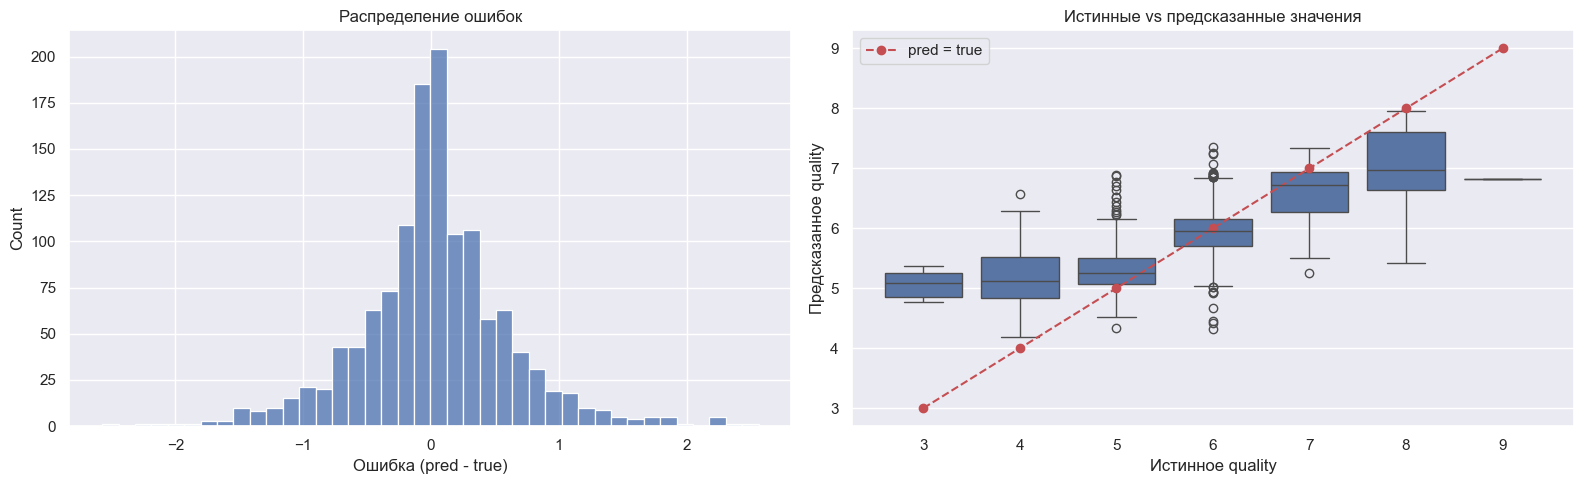

In [37]:
qualities = sorted(errors["true"].unique())

fig, axs = plt.subplots(figsize=(16, 5), ncols=2)
sns.histplot(errors["error"], bins=40, ax=axs[0])
axs[0].set_xlabel("Ошибка (pred - true)")
axs[0].set_title("Распределение ошибок")

sns.boxplot(data=errors, x="true", y="pred", color="C0", ax=axs[1])
axs[1].plot(range(len(qualities)), qualities, "r--o", label="pred = true")
axs[1].set_xlabel("Истинное quality")
axs[1].set_ylabel("Предсказанное quality")
axs[1].set_title("Истинные vs предсказанные значения")
axs[1].legend()
plt.tight_layout()

In [38]:
by_quality = errors.groupby("true").agg(
    count=("error", "size"),
    mean_pred=("pred", "mean"),
    mean_error=("error", "mean"),
    MAE=("abs_error", "mean"),
    RMSE=("error", lambda e: np.sqrt(np.mean(e ** 2))),
)
by_quality.round(3)

,count,mean_pred,mean_error,MAE,RMSE
true,,,,,
3,6,5.070,2.070,2.070,2.082
4,43,5.210,1.210,1.210,1.324
5,428,5.327,0.327,0.366,0.507
6,567,5.943,-0.057,0.323,0.434
7,216,6.580,-0.420,0.450,0.612
8,39,7.044,-0.956,0.956,1.152
9,1,6.821,-2.179,2.179,2.179


Выводы:
- Ошибки распределены примерно симметрично вокруг нуля, смещения почти нет (средняя ошибка 0.03). У 68% вин ошибка меньше полбалла, т.е. после округления они получили бы правильную оценку. Ошибка больше 1 балла — у 9.6% вин, больше 2 баллов — меньше чем у 1%.
- Но для разных оценок модель работает **неодинаково**. Для самых частых оценок 5 и 6 ошибка небольшая (RMSE 0.51 и 0.43), а дальше от центра она быстро растёт: для 4 и 8 RMSE уже 1.32 и 1.15, для 3 и 9 — больше 2.
- Видна **систематическая «тяга к центру»**: плохие вина модель переоценивает (для оценки 3 предсказывает в среднем 5.07, для 4 — 5.21), а хорошие недооценивает (для 8 в среднем 7.04, для 9 — 6.82). На графике справа медианы предсказаний лежат на более пологой линии, чем идеальная диагональ.
- Именно поэтому RMSE (0.59) настолько больше MAE (0.42): крупные ошибки сосредоточены на немногочисленных крайних винах.

**Почему модель хуже предсказывает редкие значения quality:**
1. **Мало примеров.** Вин с оценкой 3 в train около 24, с оценкой 9 — 4, а с оценками 5–6 почти 4000. Модель минимизирует среднюю ошибку по всем объектам, и ей выгоднее хорошо предсказывать массовые вина, чем подстраиваться под единичные.
2. **Деревья усредняют.** Предсказание дерева — среднее таргета в листе. Редкое вино попадает в лист вместе с похожими по химии винами, у которых оценки 5–6, и среднее сдвигается к центру.
3. **Плохие и отличные вина часто химически не отличаются от средних.** Оценка — субъективное мнение экспертов, в ней есть шум, а часть того, что влияет на оценку (аромат, вкус, баланс), в 11 измерениях не отражена.
4. **Регрессия с MSE в принципе тянет к условному среднему**: если по признакам вино похоже и на «пятёрку», и на «тройку», то оптимальный с точки зрения MSE ответ — где-то посередине, ближе к более частой оценке.

In [39]:
worst = errors.sort_values("abs_error", ascending=False).head(10)
X_test.loc[worst.index].join(worst[["true", "pred", "error"]]).round(3)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red,true,pred,error
3005,8.2,0.220,0.36,6.8,0.034,12.0,90.0,0.994,3.01,0.38,10.5,0,8,5.428,-2.572
6107,5.8,0.260,0.30,2.6,0.034,75.0,129.0,0.990,3.20,0.38,11.5,0,4,6.564,2.564
1850,8.5,0.260,0.21,16.2,0.074,41.0,197.0,0.998,3.02,0.50,9.8,0,3,5.373,2.373
5369,7.4,0.270,0.31,2.4,0.014,15.0,143.0,0.991,3.03,0.65,12.0,0,4,6.291,2.291
1374,6.8,0.815,0.00,1.2,0.267,16.0,29.0,0.995,3.32,0.51,9.8,1,3,5.278,2.278
1403,7.2,0.330,0.33,1.7,0.061,3.0,13.0,0.996,3.23,1.10,10.0,1,8,5.723,-2.277
3715,6.8,0.200,0.27,1.2,0.034,19.0,68.0,0.990,3.14,0.37,11.7,0,4,6.206,2.206
1469,7.3,0.980,0.05,2.1,0.061,20.0,49.0,0.997,3.31,0.55,9.7,1,3,5.202,2.202
3718,8.0,0.160,0.36,1.5,0.033,14.0,122.0,0.994,3.20,0.39,10.3,0,4,6.186,2.186
2426,7.4,0.240,0.36,2.0,0.031,27.0,139.0,0.991,3.28,0.48,12.5,0,9,6.821,-2.179


In [40]:
# типичные значения ключевых признаков для каждой оценки (по train), чтобы было с чем сравнивать
train.groupby(["is_red", "quality"])[["alcohol", "volatile acidity", "density", "sulphates", "chlorides", "free sulfur dioxide"]].median().round(3)

alcohol  volatile acidity  density  sulphates  chlorides  \
is_red quality                                                             
0      3         10.500             0.260    0.994      0.435      0.041   
       4         10.000             0.330    0.994      0.470      0.047   
       5          9.500             0.280    0.995      0.470      0.047   
       6         10.400             0.250    0.994      0.480      0.043   
       7         11.350             0.250    0.992      0.480      0.037   
       8         11.900             0.250    0.992      0.460      0.036   
       9         12.550             0.315    0.990      0.440      0.027   
1      3         10.075             0.818    0.998      0.555      0.090   
       4         10.400             0.670    0.996      0.560      0.076   
       5          9.700             0.580    0.997      0.580      0.081   
       6         10.500             0.495    0.997      0.640      0.078   
       7         11.600             0.370    0.996      0.730      0.073   
       8         11.700             0.360    0.995      0.740      0.070   

                free sulfur dioxide  
is_red quality                       
0      3                       33.5  
       4                       18.0  
       5                       35.0  
       6                       34.0  
       7                       33.0  
       8                       35.0  
       9                       29.5  
1      3                        5.5  
       4                       11.0  
       5                       15.0  
       6                       14.0  
       7                       11.0  
       8                       15.0

Разберу несколько вин с самыми большими ошибками (сравниваю с медианами признаков для их типа и оценки из таблицы выше):
- **№3005** (белое, реальная оценка 8, предсказано 5.43). Алкоголь 10.5 — уровень вин на 5–6 (у белых с оценкой 8 медиана 11.9), сульфаты 0.38 ниже типичного, свободного SO₂ мало (12). По признакам, которые модель считает главными, это обычное среднее вино, и понять, за что эксперты поставили 8, модель не может. Скорее всего, качество этого вина определяется тем, чего нет в данных (аромат, вкус), или это шум в оценке.
- **№6107** и **№5369** (белые, оценка 4, предсказано 6.56 и 6.29) — обратная ситуация. Алкоголь 11.5 и 12.0, как у хороших вин, летучая кислотность обычная (0.26–0.27). У этих вин нет ни одного из «дефектов», которые модель умеет распознавать, поэтому она ставит им хорошую оценку. Что не понравилось экспертам, из химии не видно.
- **№1374** и **№1469** (красные, оценка 3, предсказано ~5.2–5.3). Здесь модель правильно увидела проблему: очень высокая летучая кислотность (0.815 и 0.98, у красных с оценкой 5 медиана 0.58), у №1374 ещё и очень много хлоридов (0.267). Поэтому предсказание ниже среднего, но до 3 модель не дотягивает: красных вин с оценкой 3 в train всего несколько, и в листьях деревьев они усредняются с винами на 5.
- **№1850** (белое, оценка 3, предсказано 5.37): много сахара (16.2) и total sulfur dioxide (197), невысокий алкоголь 9.8. Похожие по химии вина в train в основном получают 5, так что для модели это типичное «пятёрочное» вино.
- **№2426** (белое, оценка 9, предсказано 6.82): высокий алкоголь (12.5), и модель дала ему одну из самых высоких оценок, но до 9 не дотянула: вин с такой оценкой в train всего 4, и они усредняются с винами на 7–8.

Общая картина: крупные ошибки — это либо редкие крайние оценки, до которых модель «не дотягивается» из-за усреднения, либо вина, у которых химический профиль типичен для другой оценки (тогда причина вне признаков или в субъективности оценки).

Отдельно проверю, насколько на оценку влияют повторы, найденные в начале: посчитаю ошибку отдельно для тестовых вин, у которых есть точная копия (по признакам) в train, и для остальных. Для сравнения — для всех трёх моделей.

In [41]:
train_rows = set(map(tuple, X_train.values))
has_copy = np.array([tuple(row) in train_rows for row in X_test.values])
print("Доля тестовых вин, у которых есть копия в train: %.3f" % has_copy.mean())

copy_check = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    copy_check[name] = {
        "RMSE (весь test)": root_mean_squared_error(y_test, y_pred),
        "RMSE (есть копия в train)": root_mean_squared_error(y_test[has_copy], y_pred[has_copy]) if has_copy.sum() > 0 else np.nan,
        "RMSE (нет копии в train)": root_mean_squared_error(y_test[~has_copy], y_pred[~has_copy]),
    }
pd.DataFrame(copy_check).T.round(4)

Доля тестовых вин, у которых есть копия в train: 0.275


,RMSE (весь test),RMSE (есть копия в train),RMSE (нет копии в train)
Linear Regression,0.728,0.7108,0.7344
Random Forest,0.601,0.2683,0.6861
Gradient Boosting,0.592,0.1852,0.6857


Это важный результат:
- У 27.5% тестовых вин есть точная копия в train (это те самые дубликаты из части 1).
- На таких винах лес и бустинг почти не ошибаются (RMSE 0.27 и 0.19): они фактически вспоминают оценку копии. Линейная регрессия запоминать не умеет, и у неё ошибка на копиях почти такая же, как на остальных (0.71 против 0.73).
- На винах **без копии** в train RMSE у леса и бустинга одинаковый — 0.686. Это честная оценка качества на действительно новых винах. Порог 0.70 она всё ещё проходит, но с небольшим запасом. На новых винах выигрыш деревьев относительно линейной регрессии — 0.734 → 0.686, а не 0.728 → 0.592, как в общей таблице.
- Получается, что разница между бустингом и лесом в итоговой таблице почти целиком набирается на копиях: бустинг лучше «запоминает» повторы, а на новых винах модели одинаковые.

Итого: общий тестовый RMSE 0.592 корректен для выборки, устроенной как исходный датасет (с повторами), но для новых, ранее не встречавшихся вин надо ориентироваться на ~0.69. Это же объясняет, почему подбор гиперпараметров выбрал очень глубокие деревья и маленькие листья: в кросс-валидации повторы тоже попадают в разные фолды, и запоминать выгодно. Если запустить ноутбук без дубликатов (строка в части 1), этого эффекта не будет, и качество будет примерно как в последней колонке (около 0.68–0.69).

# Итоги

| Модель | RMSE | MAE |
|---|---|---|
| Baseline (среднее по train) | 0.874 | 0.686 |
| Linear Regression | 0.728 | 0.568 |
| Random Forest | 0.601 | 0.433 |
| Gradient Boosting | 0.592 | 0.416 |

- Красное и белое вино объединены в одну таблицу, тип закодирован признаком `is_red`. Разбиение 80/20 со стратификацией по `quality`, `random_state=42`. Все решения приняты по 5-fold CV на train, гиперпараметры подобраны случайным поиском (`RandomizedSearchCV`), тест использован только для финальной оценки.
- Все модели лучше baseline. Порог RMSE < 0.70 проходят Random Forest и Gradient Boosting, лучшая модель — Gradient Boosting (RMSE = 0.592, MAE = 0.416).
- Линейная регрессия недообучена: зависимости в данных нелинейные и разные для красного и белого вина, а деревья находят их сами.
- Самые важные признаки у всех моделей — `alcohol` и `volatile acidity`, что совпадает с EDA. Но важность признаков не означает причинную связь.
- Хуже всего модель предсказывает редкие оценки (3–4 и 8–9) и тянет предсказания к центру.
- У ~27% тестовых вин есть копия в train, и на них модели на деревьях почти не ошибаются. На новых винах честный RMSE ≈ 0.69 — всё ещё ниже порога, но запас небольшой.